# 04 — CODE-15% Anomalies, Error Labels Catalog & Waveform Examples

Catalog of all `12` `err_*` flags and `4` `severity_tier`s in `code15/quality/error_labels.csv.gz` across all `345,779` CODE-15% exams, plus real `400 Hz` anomaly waveforms and `CODE15Dataset` filtering.

,flag,count,pct_of_345k
11,err_lbl_unlabeled_non_normal,173347,50.132
5,err_meta_missing_survival,112132,32.429
0,err_file_missing_hdf5_part,105779,30.592
3,err_age_pediatric,3980,1.151
4,err_age_nn_discrepancy_gt35,2609,0.755
8,err_lbl_af_with_sinus_rhythm,202,0.058
10,err_lbl_rbbb_and_lbbb_conflict,113,0.033
1,err_tbl_longitudinal_demo_conflict,68,0.020
2,err_age_missing_or_invalid,0,0.000
6,err_meta_negative_timey,0,0.000


,severity_tier,recommended_action,count,pct
0,0_clean,keep,79857,23.09
1,1_minor_warning,keep_with_cleaning,158091,45.72
2,2_moderate_anomaly,review_or_downweight,2052,0.59
3,3_severe_error,exclude,105779,30.59


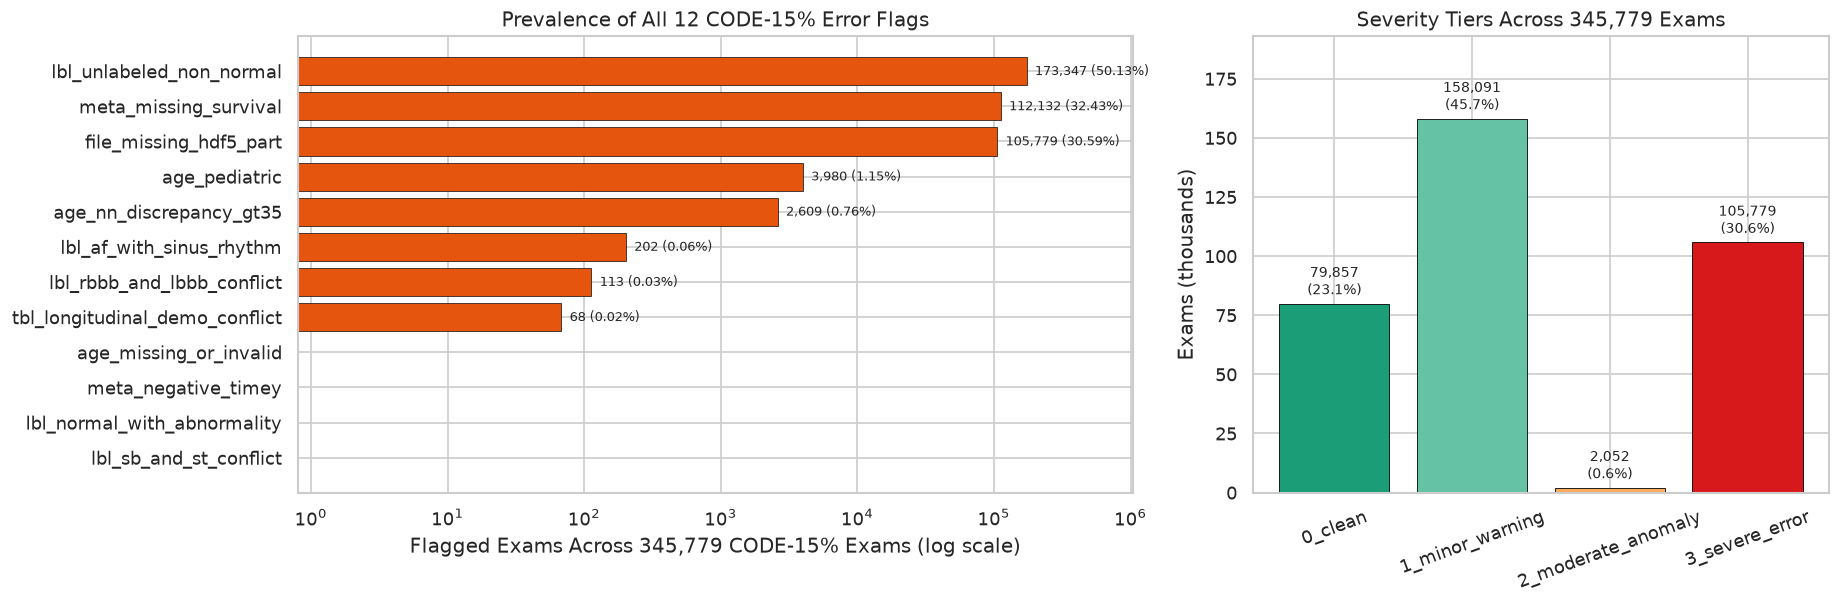

Available HDF5 exams: 240,000 | max_error_severity=2: 240,000 | max_error_severity=0 (gold): 79,857


In [1]:
import sys
import warnings
from pathlib import Path

import h5py
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns

warnings.filterwarnings("ignore", category=FutureWarning)
sns.set_theme(style="whitegrid", context="notebook", palette="deep")
plt.rcParams.update({"figure.dpi": 120, "savefig.bbox": "tight"})

_cwd = Path.cwd().resolve()
for _candidate in [_cwd, _cwd.parent, _cwd.parent.parent]:
    if (_candidate / "code15" / "quality" / "error_labels.csv.gz").exists():
        REPO_ROOT = _candidate
        break
else:
    raise FileNotFoundError(f"Could not locate code15/quality/error_labels.csv.gz from {_cwd}")

if str(REPO_ROOT) not in sys.path:
    sys.path.insert(0, str(REPO_ROOT))

from code15 import CODE15Dataset

CODE15_DIR = REPO_ROOT / "code15"
DATA_DIR = CODE15_DIR / "data"
QUALITY_DIR = CODE15_DIR / "quality"
LEADS = CODE15Dataset.LEADS
LABEL_COLS = CODE15Dataset.LABEL_COLS

from matplotlib.patches import Patch

err_df = pd.read_csv(QUALITY_DIR / "error_labels.csv.gz", index_col="exam_id")
err_df["error_tags"] = err_df["error_tags"].fillna("")
flag_cols = [c for c in err_df.columns if c.startswith("err_")]

summary = pd.DataFrame([
    {"flag": c, "count": int(err_df[c].sum()), "pct_of_345k": round(float(err_df[c].mean() * 100), 3)}
    for c in flag_cols
]).sort_values("count", ascending=False)
display(summary)

tier_summary = err_df.groupby(["severity_tier", "recommended_action"]).size().rename("count").reset_index()
tier_summary["pct"] = (tier_summary["count"] / len(err_df) * 100).round(2)
display(tier_summary)

fig, axes = plt.subplots(1, 2, figsize=(15.5, 5.2), gridspec_kw={"width_ratios": [1.45, 1]})
pt = summary.sort_values("count", ascending=True)
axes[0].barh(pt["flag"].str.replace("^err_", "", regex=True), pt["count"], color="#e6550d", edgecolor="black", lw=0.4)
axes[0].set_xscale("log")
axes[0].set_xlabel("Flagged Exams Across 345,779 CODE-15% Exams (log scale)")
axes[0].set_title("Prevalence of All 12 CODE-15% Error Flags")
for i, (cnt, pct) in enumerate(zip(pt["count"], pt["pct_of_345k"])):
    if cnt > 0:
        axes[0].text(cnt * 1.15, i, f"{cnt:,} ({pct:.2f}%)", va="center", fontsize=8)
axes[0].set_xlim(0.8, len(err_df) * 3.0)

tv = err_df["severity_tier"].value_counts().sort_index()
axes[1].bar(tv.index, tv.values / 1000.0, color=["#1b9e77", "#66c2a5", "#fdae61", "#d7191c"], edgecolor="black", lw=0.5)
axes[1].set_ylabel("Exams (thousands)")
axes[1].set_title("Severity Tiers Across 345,779 Exams")
axes[1].tick_params(axis="x", rotation=20)
for i, v in enumerate(tv.values):
    axes[1].text(i, v / 1000.0 + 4, f"{v:,}\n({v/len(err_df)*100:.1f}%)", ha="center", fontsize=8.5)
axes[1].set_ylim(0, tv.max() / 1000.0 * 1.22)

plt.tight_layout()
plt.show()

# Live CODE15Dataset filtering demonstration
ds_avail = CODE15Dataset(only_available_parts=True, load_error_labels=True)
ds_clean = CODE15Dataset(only_available_parts=True, max_error_severity=2)
ds_gold  = CODE15Dataset(only_available_parts=True, max_error_severity=0)
print(f"Available HDF5 exams: {len(ds_avail):,} | max_error_severity=2: {len(ds_clean):,} | max_error_severity=0 (gold): {len(ds_gold):,}")